In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

%cd /groups/cress/projects/efactors/jack/insertion_mapping/data/community_editing/DKDTH4

/groups/cress/projects/efactors/jack/insertion_mapping/data/community_editing/DKDTH4


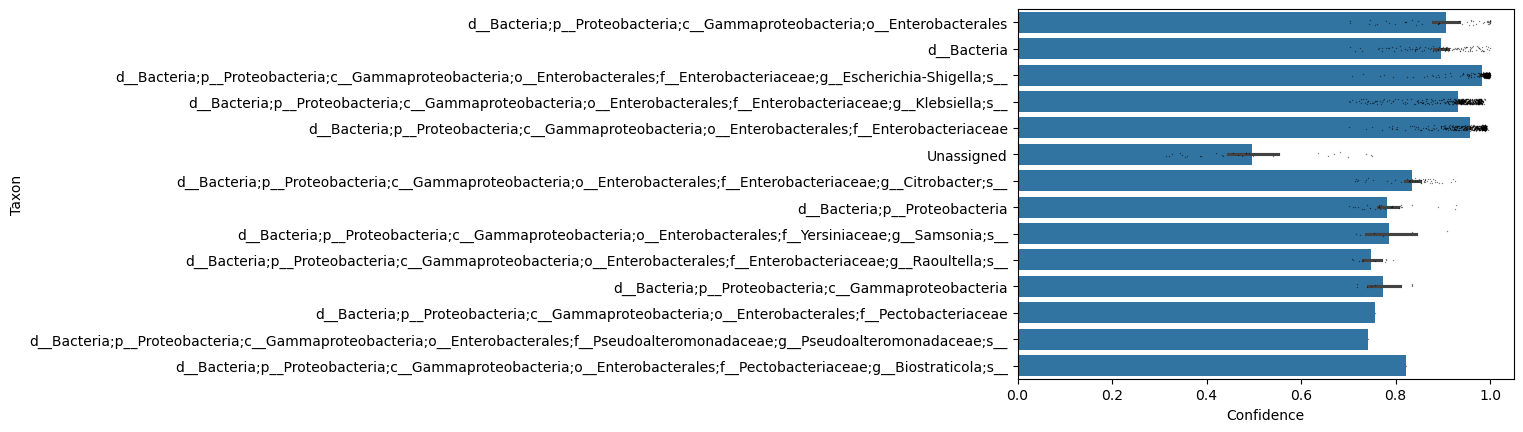

In [2]:
df = pd.read_csv("taxonomy/taxonomy.tsv", sep="\t")

sns.barplot(df, y="Taxon", x="Confidence")
sns.stripplot(df, y="Taxon", x="Confidence", c='k', alpha=0.5, s=1)
plt.show()
# df[df["Taxon"] == "d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rickettsiales;f__Mitochondria;g__Mitochondria;s__"]
# df.groupby("Taxon")["Confidence"].std()

In [3]:
tax = pd.read_csv("taxonomy/taxonomy_table.tsv", sep="\t")
split_taxa = tax["classification"].str.split(";s", expand=True)[0].str.split(";", ).values#[:, -1]#.iloc[:, -1]
simple_classification = [i[-1] for i in split_taxa]
tax["classification"] = simple_classification

# Deprecated QC

In [ ]:
from Bio import SeqIO

le_contain = SeqIO.parse("LE_containing_amplicons.fasta", "fasta")
all_reads = [i for i in SeqIO.parse("DKDTH4_1_MCKanCm_gPCR.fastq", "fastq")]

le_contain_ids = [i.id for i in le_contain]
reads_no_le = []
full_le = []
for record in all_reads:
    if record.id not in le_contain_ids:
        # print(record.id)
        reads_no_le.append(record)
    else:
        full_le.append(record)
print(f"Found {len(reads_no_le)} reads without LE")
with open("reads_no_LE.fasta", "w") as f:
    SeqIO.write(reads_no_le, f, "fasta")
with open("reads_LE.fasta", "w") as f:
    SeqIO.write(full_le, f, "fasta")

In [ ]:
# from Bio import pairwise2
# from Bio.pairwise2 import format_alignment

# le = SeqIO.read("input/LE.fasta", "fasta").seq
# match_score = 1
# mismatch_score = -1
# gap_open = -10   # very high penalty
# gap_extend = -1  # high extension penalty


# for record in full_le:
#     print(record.id)
#     alignments = pairwise2.align.globalms(record.seq, le, match_score, mismatch_score, gap_open, gap_extend)
#     for a in alignments:
#         print(format_alignment(*a))
#     alignments = pairwise2.align.globalms(record.seq, le.reverse_complement(), match_score, mismatch_score, gap_open, gap_extend)
#     for a in alignments:
#         print(format_alignment(*a))




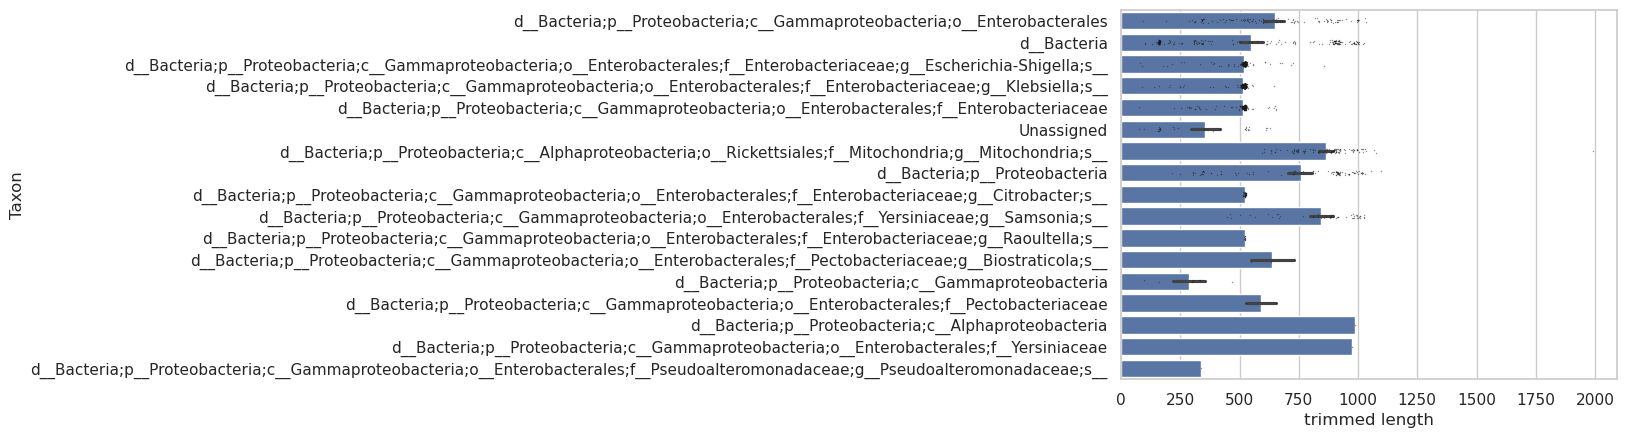

In [ ]:
nonchimeras_trimmed = SeqIO.parse("nonchimeras.fasta", "fasta")
nonchimeras_trimmed = [i for i in nonchimeras_trimmed]
trimmed_lens, nonchimerids = [], []

for i in nonchimeras_trimmed:
    trimmed_lens.append(len(i.seq))
    nonchimerids.append(i.id)

df["trimmed length"] = df["Feature ID"].map(dict(zip(nonchimerids, trimmed_lens)))

sns.barplot(df, y="Taxon", x="trimmed length")
sns.stripplot(df, y="Taxon", x="trimmed length", c='k', alpha=0.5, s=1)
plt.show()

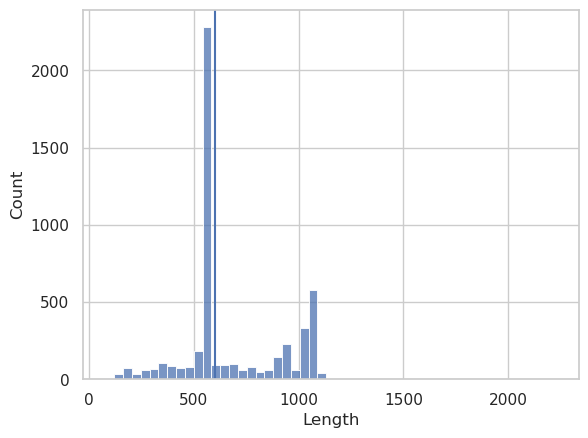

In [ ]:
allids = [i.id for i in all_reads]
alllens = [len(i.seq) for i in all_reads]
length_dict = dict(zip(allids, alllens))

reads = pd.DataFrame({"Length": length_dict}).reset_index().rename(columns={"index": "id"})
sns.histplot(reads, x="Length")
plt.axvline(600)
plt.show()

In [ ]:
(reads["Length"] > 600).value_counts()
reads

,id,Length
0,0_DKDTH4_1,287
1,1_DKDTH4_1,199
2,2_DKDTH4_1,126
3,3_DKDTH4_1,280
4,4_DKDTH4_1,255
...,...,...
4995,4995_DKDTH4_1,1067
4996,4996_DKDTH4_1,522
4997,4997_DKDTH4_1,556
4998,4998_DKDTH4_1,1053


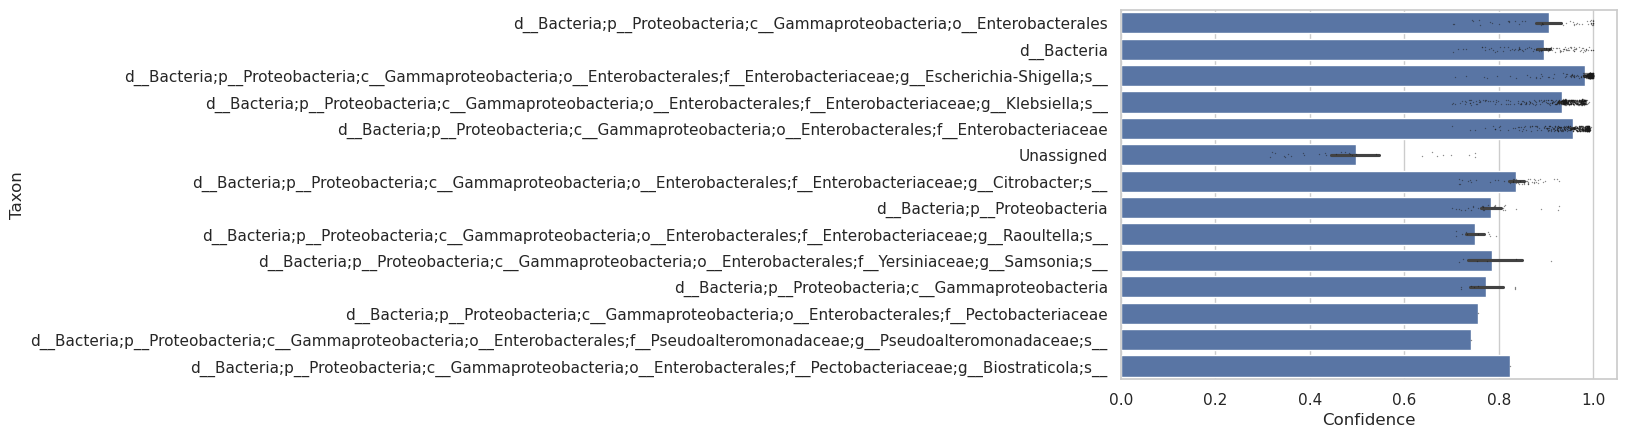

In [ ]:
df["Read Length"] = df["Feature ID"].map(length_dict)
df_length_filter = df[df["Read Length"] <= 600].copy()
sns.barplot(df_length_filter, y="Taxon", x="Confidence")
sns.stripplot(df_length_filter, y="Taxon", x="Confidence", c='k', alpha=0.5, s=1)
plt.show()

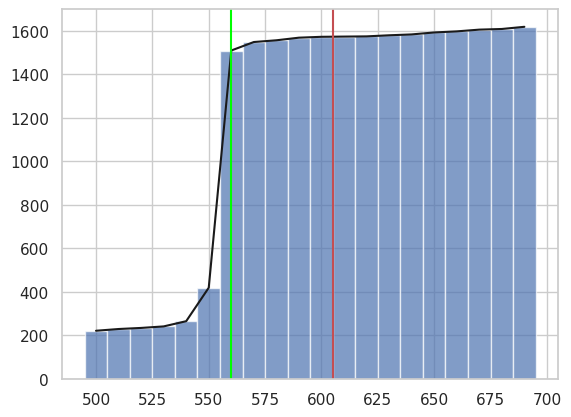

In [ ]:

lcheck = lambda x: (df["Read Length"] <= x).sum() #/ df.shape[0]
# pd.concat([lcheck(i) for i in np.arange(500, 700, 10)], axis=1)
xval = np.arange(500, 700, 10)
cts = [lcheck(i) for i in xval]
plt.bar(xval, cts, width=10, alpha=.7)
plt.plot(xval, cts, c='k')
plt.axvline(550 + 55, c='r')
plt.axvline(550 + 10, c='lime')
plt.show()
# (df["Read Length"] <= 500).value_counts()
# np.apply_along_axis(lambda x: (df["Read Length"] <= x).value_counts(), 0, np.arange(500, 700, 10))

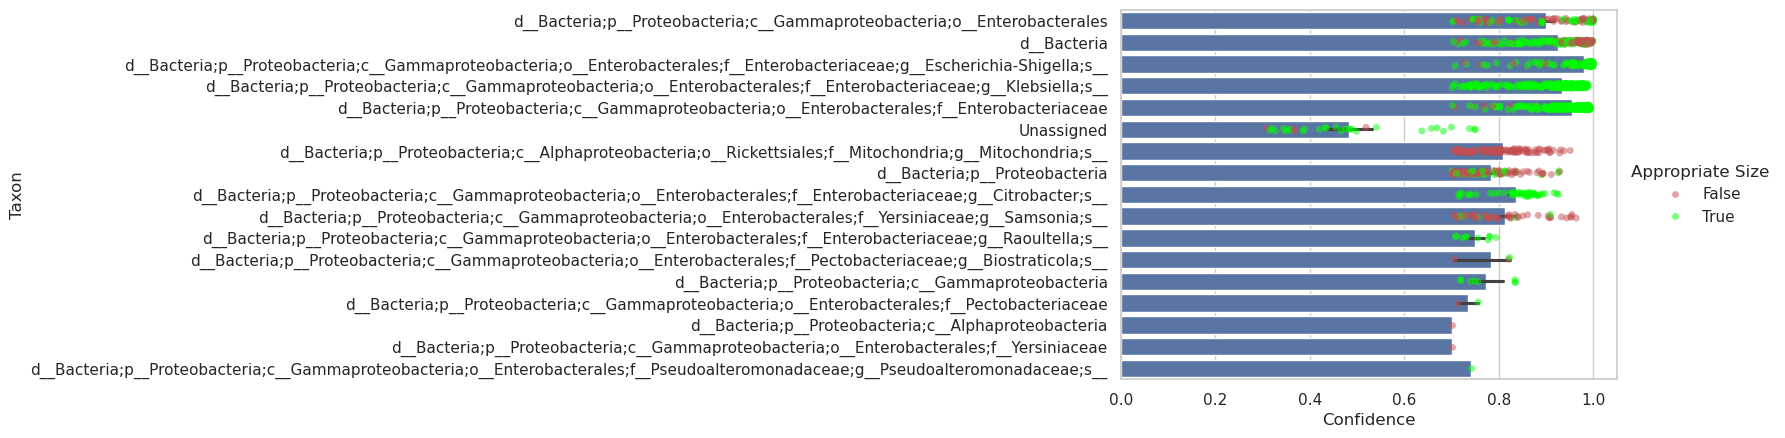

In [ ]:
df["Appropriate Size"] = df["Read Length"] <= 600
sns.barplot(df, y="Taxon", x="Confidence")
sns.stripplot(df, y="Taxon", x="Confidence", c='k', alpha=0.5, s=5, hue="Appropriate Size", palette=["r", "lime"], hue_order=[False, True])
plt.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5), title="Appropriate Size")
plt.show()
